# Hotel Booking Cancellation Prediction — Machine Learning

**Đồ án môn Machine Learning | Lộ trình 4 ngày 29/10–01/11/2026**

**Mục tiêu:** Dự đoán `is_canceled` (1: hủy, 0: không hủy) từ các thuộc tính dự kiến biết tại thời điểm đặt phòng.

- **Ngày 1:** Nạp dữ liệu, kiểm tra chất lượng, EDA, chọn features.
- **Ngày 2:** Pipeline xử lý dữ liệu, chia train/validation/test, huấn luyện 4 mô hình (gồm baseline).
- **Ngày 3:** Tối ưu nhẹ (tùy chọn), đánh giá test **một lần**, giải thích mô hình, lưu artifacts.
- **Ngày 4:** Dùng kết quả thực tế để viết báo cáo, slide và demo tùy chọn.

**Lưu ý học thuật:** Dataset gốc được trích xuất với thời điểm tham chiếu trước ngày khách đến; **không phải mọi trường đều có sẵn ngay khi đặt phòng**. Ta chủ động bỏ các trường rõ ràng có thông tin hậu nghiệm (`reservation_status`, `reservation_status_date`, `booking_changes`, `assigned_room_type`, ...) để hạn chế **data leakage**. Dù vậy, tính sẵn có của từng biến còn tùy quy trình nghiệp vụ; đây là giới hạn cần ghi vào báo cáo.

Nguồn: https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand  
Bài báo gốc: https://pmc.ncbi.nlm.nih.gov/articles/PMC6297060/

In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive')

print("Drive connected:", os.path.exists('/content/drive/MyDrive'))

Mounted at /content/drive
Drive connected: True


In [ ]:
from google.colab import drive
import os
import pandas as pd

drive.mount('/content/drive')

file_path = "/content/drive/MyDrive/MyDrive/Hotel_Booking_ML/data/hotel_bookings.csv"

print("CSV exists:", os.path.exists(file_path))

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CSV exists: True
Dataset shape: (119390, 32)


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

file_path = "/content/drive/MyDrive/MyDrive/Hotel_Booking_ML/data/hotel_bookings.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [ ]:
# STEP 2: DATA UNDERSTANDING

print("=== THÔNG TIN DATASET ===")
df.info()

print("\n=== KIỂU DỮ LIỆU ===")
display(df.dtypes.to_frame("Data Type"))

print("\n=== THỐNG KÊ CƠ BẢN ===")
display(df.describe(include="all").T)

=== THÔNG TIN DATASET ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int

,Data Type
hotel,object
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,object
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64



=== THỐNG KÊ CƠ BẢN ===


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,119390,2,City Hotel,79330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_canceled,119390.0,NaN,NaN,NaN,0.370416,0.482918,0.0,0.0,0.0,1.0,1.0
lead_time,119390.0,NaN,NaN,NaN,104.011416,106.863097,0.0,18.0,69.0,160.0,737.0
arrival_date_year,119390.0,NaN,NaN,NaN,2016.156554,0.707476,2015.0,2016.0,2016.0,2017.0,2017.0
arrival_date_month,119390,12,August,13877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_date_week_number,119390.0,NaN,NaN,NaN,27.165173,13.605138,1.0,16.0,28.0,38.0,53.0
arrival_date_day_of_month,119390.0,NaN,NaN,NaN,15.798241,8.780829,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,119390.0,NaN,NaN,NaN,0.927599,0.998613,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,119390.0,NaN,NaN,NaN,2.500302,1.908286,0.0,1.0,2.0,3.0,50.0
adults,119390.0,NaN,NaN,NaN,1.856403,0.579261,0.0,2.0,2.0,2.0,55.0


In [ ]:
# STEP 3: MISSING VALUES

missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percent": df.isnull().mean() * 100
})

missing = missing[missing["Missing Count"] > 0]
missing = missing.sort_values(
    by="Missing Count",
    ascending=False
)

display(missing.round(2))

print("Số dòng trùng lặp:", df.duplicated().sum())

,Missing Count,Missing Percent
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


Số dòng trùng lặp: 31994


=== PHÂN PHỐI NHÃN ===
is_canceled
0    75166
1    44224
Name: count, dtype: int64

=== TỶ LỆ PHẦN TRĂM ===
is_canceled
0    62.96
1    37.04
Name: proportion, dtype: float64


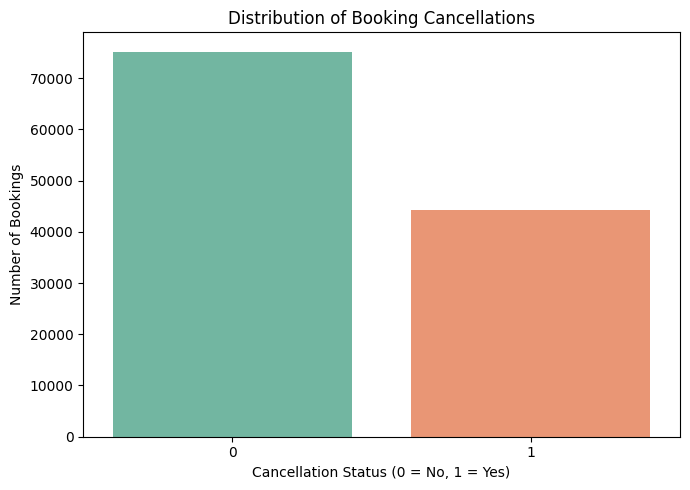

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print("=== PHÂN PHỐI NHÃN ===")
print(df["is_canceled"].value_counts())

print("\n=== TỶ LỆ PHẦN TRĂM ===")
print(
    (df["is_canceled"].value_counts(normalize=True) * 100)
    .round(2)
)

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="is_canceled",
    hue="is_canceled",
    palette="Set2",
    legend=False
)

plt.title("Distribution of Booking Cancellations")
plt.xlabel("Cancellation Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Bookings")
plt.tight_layout()
plt.show()

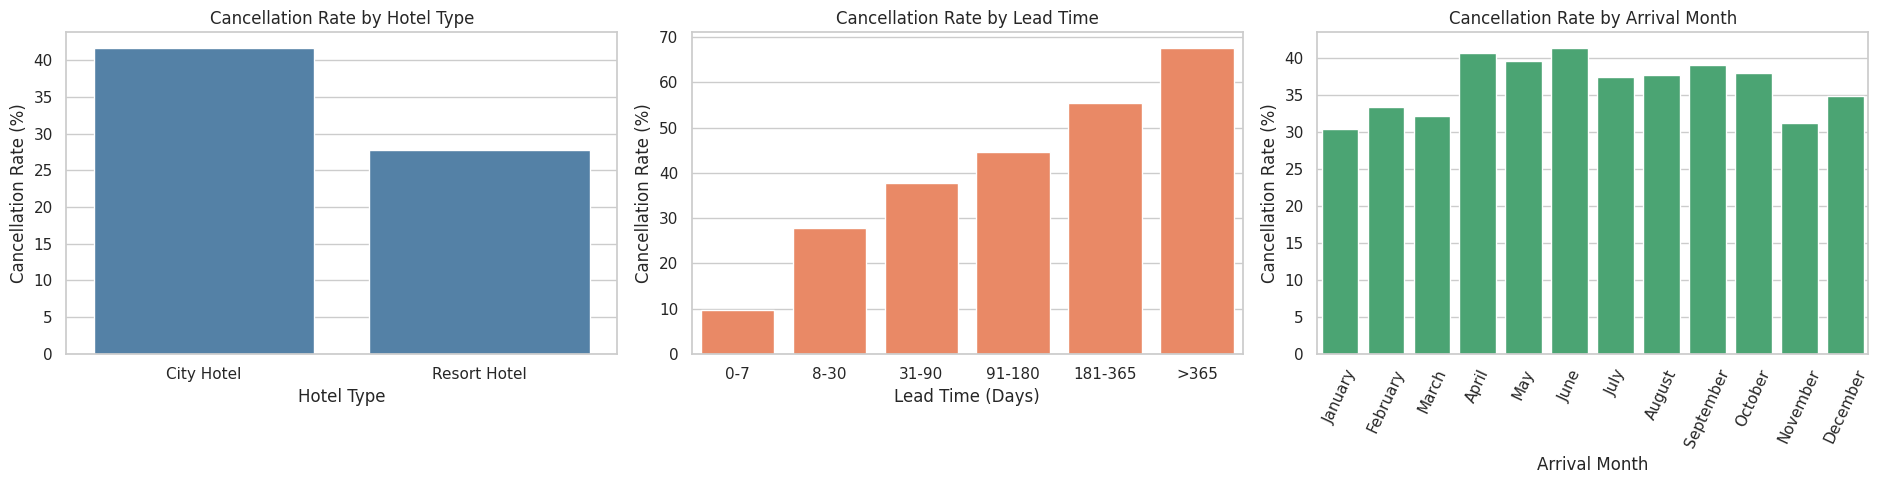


Cancellation Rate by Hotel:


,is_canceled
hotel,
City Hotel,41.73
Resort Hotel,27.76



Cancellation Rate by Lead Time:


,is_canceled
lead_time_group,
0-7,9.63
8-30,27.86
31-90,37.70
91-180,44.71
181-365,55.45
>365,67.66



Cancellation Rate by Month:


,is_canceled
arrival_date_month,
January,30.48
February,33.42
March,32.15
April,40.80
May,39.67
June,41.46
July,37.45
August,37.75
September,39.17


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# 1. Cancellation Rate by Hotel Type
hotel_rate = df.groupby("hotel")["is_canceled"].mean() * 100

sns.barplot(
    x=hotel_rate.index,
    y=hotel_rate.values,
    ax=axes[0],
    color="steelblue"
)
axes[0].set_title("Cancellation Rate by Hotel Type")
axes[0].set_ylabel("Cancellation Rate (%)")
axes[0].set_xlabel("Hotel Type")

# 2. Cancellation Rate by Lead Time
lead_bins = [-1, 7, 30, 90, 180, 365, float("inf")]
lead_labels = ["0-7", "8-30", "31-90", "91-180", "181-365", ">365"]

eda_df = df.copy()
eda_df["lead_time_group"] = pd.cut(
    eda_df["lead_time"],
    bins=lead_bins,
    labels=lead_labels
)

lead_rate = (
    eda_df.groupby(
        "lead_time_group",
        observed=True
    )["is_canceled"].mean() * 100
)

sns.barplot(
    x=lead_rate.index,
    y=lead_rate.values,
    ax=axes[1],
    color="coral"
)
axes[1].set_title("Cancellation Rate by Lead Time")
axes[1].set_ylabel("Cancellation Rate (%)")
axes[1].set_xlabel("Lead Time (Days)")

# 3. Cancellation Rate by Month
months = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

month_rate = (
    df.groupby("arrival_date_month")["is_canceled"]
    .mean().reindex(months) * 100
)

sns.barplot(
    x=month_rate.index,
    y=month_rate.values,
    ax=axes[2],
    color="mediumseagreen"
)
axes[2].set_title("Cancellation Rate by Arrival Month")
axes[2].set_ylabel("Cancellation Rate (%)")
axes[2].set_xlabel("Arrival Month")
axes[2].tick_params(axis="x", rotation=65)

plt.tight_layout()
plt.savefig("eda_cancellation_analysis.png", dpi=200)
plt.show()

print("\nCancellation Rate by Hotel:")
display(hotel_rate.round(2))

print("\nCancellation Rate by Lead Time:")
display(lead_rate.round(2))

print("\nCancellation Rate by Month:")
display(month_rate.round(2))

In [ ]:
# STEP 5: FEATURE SELECTION

target = "is_canceled"

features = [
    "hotel",
    "lead_time",
    "arrival_date_month",
    "arrival_date_year",
    "arrival_date_week_number",
    "arrival_date_day_of_month",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "meal",
    "country",
    "market_segment",
    "distribution_channel",
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "reserved_room_type",
    "deposit_type",
    "customer_type"
]

X = df[features].copy()
y = df[target].copy()

print("Feature matrix:", X.shape)
print("Target:", y.shape)
print("Number of features:", len(features))

Feature matrix: (119390, 21)
Target: (119390,)
Number of features: 21


In [ ]:
# STEP 6: TRAIN / VALIDATION / TEST SPLIT

from sklearn.model_selection import GroupShuffleSplit
import pandas as pd

# Tạo group cho các bản ghi giống hệt nhau
group_data = pd.concat([X, y.rename(target)], axis=1)
groups = pd.util.hash_pandas_object(
    group_data.fillna("__MISSING__"),
    index=False
).to_numpy()

# 80% train+validation / 20% test
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_val_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train_val = X.iloc[train_val_idx]
X_test = X.iloc[test_idx]
y_train_val = y.iloc[train_val_idx]
y_test = y.iloc[test_idx]

print("Train + Validation:", X_train_val.shape)
print("Test:", X_test.shape)

print("\nTarget distribution:")
print("Train + Val:", y_train_val.mean().round(4))
print("Test:", y_test.mean().round(4))

Train + Validation: (95173, 21)
Test: (24217, 21)

Target distribution:
Train + Val: 0.3685
Test: 0.3778


In [ ]:
# STEP 7: SPLIT TRAIN / VALIDATION

from sklearn.model_selection import GroupShuffleSplit
import numpy as np

# Sử dụng lại group ID của các dòng trong train_val
train_val_groups = groups[train_val_idx]

val_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    val_splitter.split(
        X_train_val,
        y_train_val,
        groups=train_val_groups
    )
)

X_train = X_train_val.iloc[train_idx]
X_val = X_train_val.iloc[val_idx]

y_train = y_train_val.iloc[train_idx]
y_val = y_train_val.iloc[val_idx]

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nCancellation Rate:")
print("Train:", round(y_train.mean() * 100, 2), "%")
print("Validation:", round(y_val.mean() * 100, 2), "%")
print("Test:", round(y_test.mean() * 100, 2), "%")

Train: (76060, 21)
Validation: (19113, 21)
Test: (24217, 21)

Cancellation Rate:
Train: 36.57 %
Validation: 37.98 %
Test: 37.78 %


In [ ]:
# STEP 8: DATA PREPROCESSING

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numeric Features:", numeric_features)
print("\nCategorical Features:", categorical_features)

# Numerical Pipeline
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical Pipeline
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Combine
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("\nPreprocessing Pipeline created successfully!")

Numeric Features: ['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled']

Categorical Features: ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type']

Preprocessing Pipeline created successfully!


In [ ]:
# STEP 9: LOGISTIC REGRESSION

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

lr_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train trên training set
lr_model.fit(X_train, y_train)

# Dự đoán validation set
y_pred = lr_model.predict(X_val)
y_prob = lr_model.predict_proba(X_val)[:, 1]

print("=== LOGISTIC REGRESSION RESULTS ===")
print("Accuracy :", round(accuracy_score(y_val, y_pred), 4))
print("Precision:", round(precision_score(y_val, y_pred), 4))
print("Recall   :", round(recall_score(y_val, y_pred), 4))
print("F1-score :", round(f1_score(y_val, y_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_val, y_prob), 4))

=== LOGISTIC REGRESSION RESULTS ===
Accuracy : 0.7855
Precision: 0.806
Recall   : 0.5734
F1-score : 0.6701
ROC-AUC  : 0.8561


In [ ]:
# STEP 10: DECISION TREE

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

dt_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=12,
        min_samples_leaf=20,
        random_state=42
    ))
])

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_val)
dt_prob = dt_model.predict_proba(X_val)[:, 1]

print("=== DECISION TREE RESULTS ===")
print("Accuracy :", round(accuracy_score(y_val, dt_pred), 4))
print("Precision:", round(precision_score(y_val, dt_pred), 4))
print("Recall   :", round(recall_score(y_val, dt_pred), 4))
print("F1-score :", round(f1_score(y_val, dt_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_val, dt_prob), 4))

=== DECISION TREE RESULTS ===
Accuracy : 0.7962
Precision: 0.814
Recall   : 0.6006
F1-score : 0.6912
ROC-AUC  : 0.8768


In [ ]:
import os

print(os.path.exists("/content/hotel_bookings.csv"))

False


In [ ]:
required_vars = [
    "X_train",
    "y_train",
    "X_val",
    "y_val",
    "preprocessor",
    "lr_model"
]

for var in required_vars:
    print(var, "OK" if var in globals() else "MISSING")

X_train OK
y_train OK
X_val OK
y_val OK
preprocessor OK
lr_model OK


In [ ]:
# STEP 11: RANDOM FOREST

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

rf_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=150,
        max_depth=18,
        min_samples_leaf=5,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ))
])

# Training
rf_model.fit(X_train, y_train)

# Validation predictions
rf_pred = rf_model.predict(X_val)
rf_prob = rf_model.predict_proba(X_val)[:, 1]

# Evaluation
print("=== RANDOM FOREST RESULTS ===")

print("Accuracy :", round(accuracy_score(y_val, rf_pred), 4))
print("Precision:", round(precision_score(y_val, rf_pred), 4))
print("Recall   :", round(recall_score(y_val, rf_pred), 4))
print("F1-score :", round(f1_score(y_val, rf_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_val, rf_prob), 4))

=== RANDOM FOREST RESULTS ===
Accuracy : 0.7943
Precision: 0.9433
Recall   : 0.4879
F1-score : 0.6431
ROC-AUC  : 0.8923


In [ ]:
# STEP 12: MODEL COMPARISON

import pandas as pd

models = {
    "Logistic Regression": lr_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}

results = []

for name, model in models.items():
    pred = model.predict(X_val)
    prob = model.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred),
        "Recall": recall_score(y_val, pred),
        "F1-score": f1_score(y_val, pred),
        "ROC-AUC": roc_auc_score(y_val, prob)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-score",
    ascending=False
)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
1,Decision Tree,0.7962,0.8140,0.6006,0.6912,0.8768
0,Logistic Regression,0.7855,0.8060,0.5734,0.6701,0.8561
2,Random Forest,0.7943,0.9433,0.4879,0.6431,0.8923


In [ ]:
models = {
    "Logistic Regression": lr_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}

for name, model in models.items():
    required = list(
        model.named_steps["preprocessor"].feature_names_in_
    )

    missing = sorted(set(required) - set(X_val.columns))
    extra = sorted(set(X_val.columns) - set(required))

    print(f"\n=== {name} ===")
    print("Required:", len(required))
    print("Missing:", missing)
    print("Extra:", extra)

print("\nCurrent X_train:", X_train.shape)
print("Current X_val:", X_val.shape)
print("Current X_test:", X_test.shape)


=== Logistic Regression ===
Required: 21
Missing: []
Extra: []

=== Decision Tree ===
Required: 21
Missing: []
Extra: []

=== Random Forest ===
Required: 21
Missing: []
Extra: []

Current X_train: (76060, 21)
Current X_val: (19113, 21)
Current X_test: (24217, 21)


In [ ]:
print("X_train columns:", X_train.columns.tolist())
print("X_val columns:", X_val.columns.tolist())

assert set(X_train.columns) == set(X_val.columns), \
    "Train và Validation đang có các cột khác nhau!"

print("Feature consistency OK!")

X_train columns: ['hotel', 'lead_time', 'arrival_date_month', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'deposit_type', 'customer_type']
X_val columns: ['hotel', 'lead_time', 'arrival_date_month', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'deposit_type', 'customer_type']
Feature consistency OK!


In [ ]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", DecisionTreeClassifier(
            max_depth=12,
            min_samples_leaf=20,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=150,
            max_depth=18,
            min_samples_leaf=5,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

for name, model in models.items():
    print("Training:", name)
    model.fit(X_train, y_train)

lr_model = models["Logistic Regression"]
dt_model = models["Decision Tree"]
rf_model = models["Random Forest"]

print("All models trained successfully!")

Training: Logistic Regression
Training: Decision Tree
Training: Random Forest
All models trained successfully!


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

# Kiểm tra nhất quán feature
assert X_train.columns.equals(X_val.columns)
assert X_train.columns.equals(X_test.columns)

# Xác định kiểu biến
numeric_features = X_train.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Tạo preprocessing
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Unknown"
        )),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

# Tạo 3 mô hình thống nhất
models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", DecisionTreeClassifier(
            max_depth=12,
            min_samples_leaf=20,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=150,
            max_depth=18,
            min_samples_leaf=5,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

for name, model in models.items():
    print("Training:", name)
    model.fit(X_train, y_train)

lr_model = models["Logistic Regression"]
dt_model = models["Decision Tree"]
rf_model = models["Random Forest"]

print("All models trained successfully!")

Training: Logistic Regression
Training: Decision Tree
Training: Random Forest
All models trained successfully!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import pandas as pd

results = []

for name, model in models.items():
    pred = model.predict(X_val)
    prob = model.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred),
        "Recall": recall_score(y_val, pred),
        "F1-score": f1_score(y_val, pred),
        "ROC-AUC": roc_auc_score(y_val, prob)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="F1-score",
    ascending=False
)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
1,Decision Tree,0.7962,0.8140,0.6006,0.6912,0.8768
0,Logistic Regression,0.7855,0.8060,0.5734,0.6701,0.8561
2,Random Forest,0.7943,0.9433,0.4879,0.6431,0.8923


In [ ]:
for name, model in models.items():
    required = list(
        model.named_steps["preprocessor"].feature_names_in_
    )

    print(
        name,
        "Feature match:",
        required == X_val.columns.tolist()
    )

Logistic Regression Feature match: True
Decision Tree Feature match: True
Random Forest Feature match: True


In [ ]:
# STEP 13: SAVE MODELS & RESULTS

import os
import joblib


project_dir = "/content/drive/MyDrive/MyDrive/Hotel_Booking_ML"
model_dir = os.path.join(project_dir, "models")

os.makedirs(model_dir, exist_ok=True)

# Lưu từng mô hình
for name, model in models.items():
    filename = name.lower().replace(" ", "_") + ".joblib"
    path = os.path.join(model_dir, filename)

    joblib.dump(model, path)
    print("Saved:", path)

# Lưu bảng kết quả
results_df.to_csv(
    os.path.join(model_dir, "model_comparison.csv"),
    index=False
)

# Lưu danh sách feature
with open(
    os.path.join(model_dir, "features.txt"),
    "w",
    encoding="utf-8"
) as f:
    f.write("\n".join(X_train.columns))

print("\nAll models and results saved!")

Saved: /content/drive/MyDrive/MyDrive/Hotel_Booking_ML/models/logistic_regression.joblib
Saved: /content/drive/MyDrive/MyDrive/Hotel_Booking_ML/models/decision_tree.joblib
Saved: /content/drive/MyDrive/MyDrive/Hotel_Booking_ML/models/random_forest.joblib

All models and results saved!


In [ ]:
# STEP 14: DUMMY BASELINE

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

dummy_model = DummyClassifier(
    strategy="most_frequent"
)

dummy_model.fit(X_train, y_train)

dummy_pred = dummy_model.predict(X_val)
dummy_prob = dummy_model.predict_proba(X_val)[:, 1]

baseline_result = {
    "Model": "Dummy Classifier",
    "Accuracy": accuracy_score(y_val, dummy_pred),
    "Precision": precision_score(
        y_val, dummy_pred, zero_division=0
    ),
    "Recall": recall_score(y_val, dummy_pred),
    "F1-score": f1_score(y_val, dummy_pred),
    "ROC-AUC": roc_auc_score(y_val, dummy_prob)
}

final_comparison = pd.concat(
    [results_df, pd.DataFrame([baseline_result])],
    ignore_index=True
)

display(
    final_comparison.sort_values(
        by="F1-score",
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Decision Tree,0.7962,0.8140,0.6006,0.6912,0.8768
1,Logistic Regression,0.7855,0.8060,0.5734,0.6701,0.8561
2,Random Forest,0.7943,0.9433,0.4879,0.6431,0.8923
3,Dummy Classifier,0.6202,0.0000,0.0000,0.0000,0.5000


In [ ]:
# STEP 15: FEATURE AUDIT

print("Number of features:", len(X_train.columns))

feature_audit = pd.DataFrame({
    "Feature": X_train.columns,
    "Data Type": X_train.dtypes.astype(str).values,
    "Missing %": (
        X_train.isnull().mean() * 100
    ).round(2).values
})

display(feature_audit)

Number of features: 21


,Feature,Data Type,Missing %
0,hotel,object,0.00
1,lead_time,int64,0.00
2,arrival_date_month,object,0.00
3,arrival_date_year,int64,0.00
4,arrival_date_week_number,int64,0.00
5,arrival_date_day_of_month,int64,0.00
6,stays_in_weekend_nights,int64,0.00
7,stays_in_week_nights,int64,0.00
8,adults,int64,0.00
9,children,float64,0.00


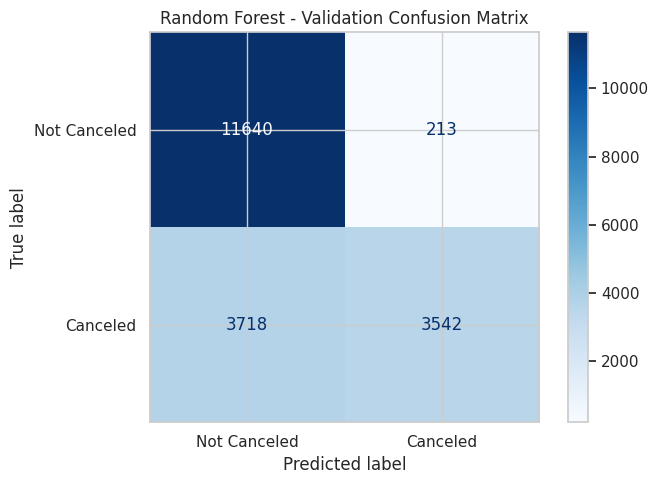

              precision    recall  f1-score   support

Not Canceled       0.76      0.98      0.86     11853
    Canceled       0.94      0.49      0.64      7260

    accuracy                           0.79     19113
   macro avg       0.85      0.73      0.75     19113
weighted avg       0.83      0.79      0.77     19113



In [ ]:
# STEP 16: CONFUSION MATRIX - VALIDATION SET

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)
import matplotlib.pyplot as plt

rf_pred = rf_model.predict(X_val)

cm = confusion_matrix(y_val, rf_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Canceled", "Canceled"]
)

fig, ax = plt.subplots(figsize=(7, 5))
disp.plot(ax=ax, cmap="Blues", values_format="d")

plt.title("Random Forest - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(
    y_val,
    rf_pred,
    target_names=["Not Canceled", "Canceled"]
))

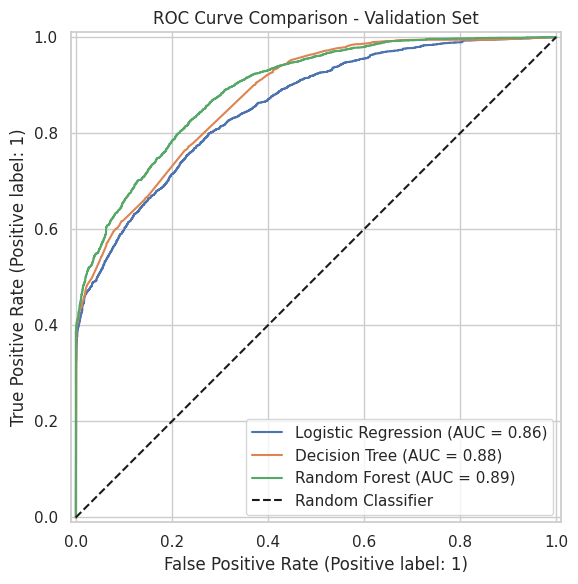

In [ ]:
# STEP 17: ROC CURVE

from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 6))

for name, model in models.items():
    RocCurveDisplay.from_estimator(
        model,
        X_val,
        y_val,
        name=name,
        ax=ax
    )

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")
plt.title("ROC Curve Comparison - Validation Set")
plt.legend()
plt.tight_layout()
plt.show()

,Feature,Importance
12,country,0.092567
19,deposit_type,0.070422
13,market_segment,0.053100
1,lead_time,0.039485
20,customer_type,0.030951
16,previous_cancellations,0.019717
3,arrival_date_year,0.010790
14,distribution_channel,0.009998
0,hotel,0.008555
17,previous_bookings_not_canceled,0.002970


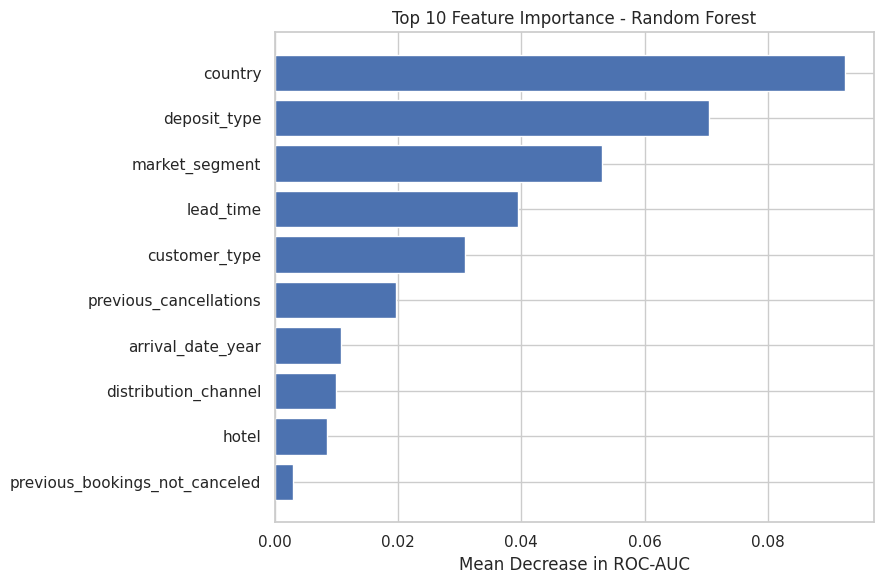

In [ ]:
# STEP 18: FEATURE IMPORTANCE

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

X_sample = X_val.sample(
    n=min(3000, len(X_val)),
    random_state=42
)
y_sample = y_val.loc[X_sample.index]

importance = permutation_importance(
    rf_model,
    X_sample,
    y_sample,
    n_repeats=3,
    random_state=42,
    scoring="roc_auc",
    n_jobs=1
)

feature_imp = pd.DataFrame({
    "Feature": X_sample.columns,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

display(feature_imp.head(10))

top_features = feature_imp.head(10).sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Mean Decrease in ROC-AUC")
plt.title("Top 10 Feature Importance - Random Forest")
plt.tight_layout()
plt.show()

In [ ]:
# STEP 19A: FEATURE ABLATION STUDY

from sklearn.base import clone

sensitive_features = [
    "total_of_special_requests",
    "required_car_parking_spaces"
]

safe_features = [
    col for col in X_train.columns
    if col not in sensitive_features
]

X_train_safe = X_train[safe_features].copy()
X_val_safe = X_val[safe_features].copy()

print("Original features:", X_train.shape[1])
print("Reduced features:", X_train_safe.shape[1])
print("Removed:", sensitive_features)

Original features: 21
Reduced features: 21
Removed: ['total_of_special_requests', 'required_car_parking_spaces']


In [ ]:
# STEP 19B: RANDOM FOREST WITHOUT TWO FEATURES

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier

num_safe = X_train_safe.select_dtypes(
    include="number"
).columns.tolist()

cat_safe = X_train_safe.select_dtypes(
    include=["object", "category"]
).columns.tolist()

preprocessor_safe = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_safe),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Unknown"
        )),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_safe)
])

rf_safe = Pipeline([
    ("preprocessor", preprocessor_safe),
    ("classifier", RandomForestClassifier(
        n_estimators=150,
        max_depth=18,
        min_samples_leaf=5,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ))
])

rf_safe.fit(X_train_safe, y_train)

safe_pred = rf_safe.predict(X_val_safe)
safe_prob = rf_safe.predict_proba(X_val_safe)[:, 1]

print("=== REDUCED FEATURE RANDOM FOREST ===")
print("Accuracy:", round(accuracy_score(y_val, safe_pred), 4))
print("Precision:", round(precision_score(y_val, safe_pred), 4))
print("Recall:", round(recall_score(y_val, safe_pred), 4))
print("F1-score:", round(f1_score(y_val, safe_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, safe_prob), 4))

=== REDUCED FEATURE RANDOM FOREST ===
Accuracy: 0.7943
Precision: 0.9433
Recall: 0.4879
F1-score: 0.6431
ROC-AUC: 0.8923


In [ ]:
# STEP 19C: ABLATION COMPARISON

ablation_results = pd.DataFrame([
    {
        "Feature Set": "Original (21)",
        "Accuracy": accuracy_score(y_val, rf_pred),
        "Precision": precision_score(y_val, rf_pred),
        "Recall": recall_score(y_val, rf_pred),
        "F1-score": f1_score(y_val, rf_pred),
        "ROC-AUC": roc_auc_score(
            y_val, rf_model.predict_proba(X_val)[:, 1]
        )
    },
    {
        "Feature Set": "Reduced (19)",
        "Accuracy": accuracy_score(y_val, safe_pred),
        "Precision": precision_score(y_val, safe_pred),
        "Recall": recall_score(y_val, safe_pred),
        "F1-score": f1_score(y_val, safe_pred),
        "ROC-AUC": roc_auc_score(y_val, safe_prob)
    }
])

display(ablation_results.round(4))

,Feature Set,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Original (21),0.7943,0.9433,0.4879,0.6431,0.8923
1,Reduced (19),0.7943,0.9433,0.4879,0.6431,0.8923


In [ ]:
# STEP 20A: THRESHOLD TUNING ON VALIDATION

import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    accuracy_score
)

# Xác suất từ mô hình 19 feature đã huấn luyện
val_probs = rf_safe.predict_proba(X_val_safe)[:, 1]

thresholds = np.round(np.arange(0.20, 0.81, 0.02), 2)
threshold_results = []

for threshold in thresholds:
    predictions = (val_probs >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

best_row = threshold_df.loc[
    threshold_df["F1-score"].idxmax()
]

best_threshold = float(best_row["Threshold"])

print("Best threshold:", best_threshold)
print("Best validation F1:", round(best_row["F1-score"], 4))

display(
    threshold_df.sort_values(
        "F1-score", ascending=False
    ).head(10).round(4)
)

Best threshold: 0.36
Best validation F1: 0.7446


,Threshold,Accuracy,Precision,Recall,F1-score
8,0.36,0.7817,0.6700,0.8380,0.7446
7,0.34,0.7726,0.6497,0.8708,0.7442
9,0.38,0.7925,0.7010,0.7913,0.7434
6,0.32,0.7586,0.6274,0.8979,0.7387
10,0.40,0.8006,0.7391,0.7342,0.7366
5,0.30,0.7467,0.6112,0.9160,0.7331
4,0.28,0.7354,0.5980,0.9255,0.7266
11,0.42,0.8073,0.7883,0.6736,0.7264
3,0.26,0.7231,0.5849,0.9333,0.7191
12,0.44,0.8098,0.8394,0.6175,0.7115


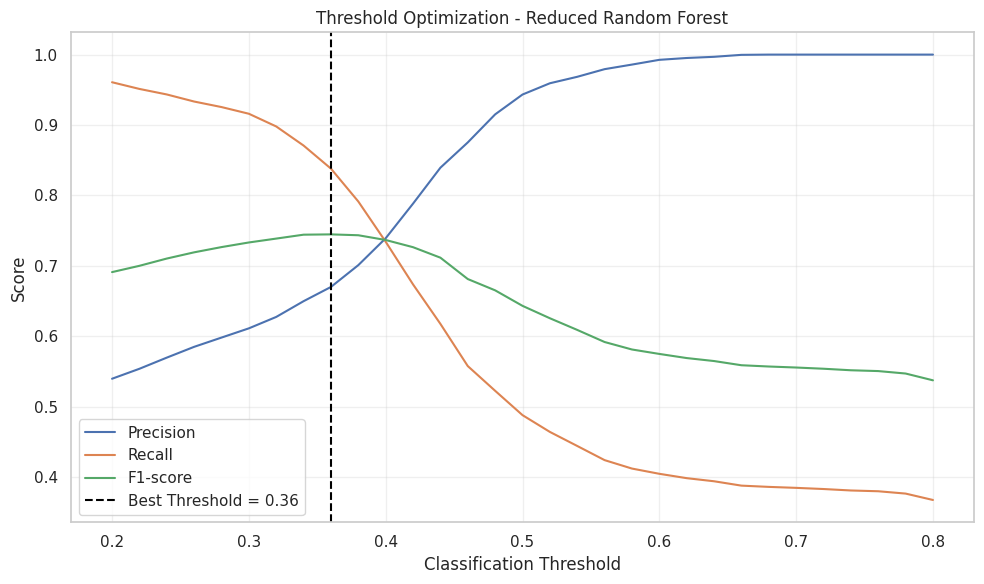

In [ ]:
# STEP 20B: THRESHOLD COMPARISON CHART

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1-score"],
    label="F1-score"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    color="black",
    label=f"Best Threshold = {best_threshold:.2f}"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Threshold Optimization - Reduced Random Forest")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# STEP 20C: DEFAULT VS OPTIMIZED THRESHOLD

comparison = threshold_df[
    threshold_df["Threshold"].isin([0.50, best_threshold])
].drop_duplicates()

display(comparison.round(4))

,Threshold,Accuracy,Precision,Recall,F1-score
8,0.36,0.7817,0.6700,0.8380,0.7446
15,0.50,0.7943,0.9433,0.4879,0.6431


In [ ]:
# STEP 21A: RANDOM FOREST HYPERPARAMETER TUNING

from sklearn.model_selection import RandomizedSearchCV
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

tuning_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor_safe)),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

param_distributions = {
    "classifier__n_estimators": [100, 150, 200],
    "classifier__max_depth": [12, 16, 20, None],
    "classifier__min_samples_leaf": [2, 5, 10],
    "classifier__max_features": ["sqrt", 0.7]
}

search = RandomizedSearchCV(
    estimator=tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=6,
    scoring="roc_auc",
    cv=3,
    random_state=42,
    n_jobs=-1,
    refit=True,
    verbose=1
)

search.fit(X_train_safe, y_train)

print("Best Parameters:", search.best_params_)
print("Best CV ROC-AUC:", round(search.best_score_, 4))

rf_tuned = search.best_estimator_

Fitting 3 folds for each of 6 candidates, totalling 18 fits


KeyboardInterrupt: 

In [ ]:
# RESTORE TUNED RANDOM FOREST
# Không chạy lại RandomizedSearchCV

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

rf_tuned = Pipeline([
    ("preprocessor", clone(preprocessor_safe)),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=2,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ))
])

rf_tuned.fit(X_train_safe, y_train)

print("Tuned Random Forest restored successfully!")
print("Train size:", X_train_safe.shape)

Tuned Random Forest restored successfully!
Train size: (76060, 21)


In [ ]:
# STEP 21B: TUNED RANDOM FOREST - VALIDATION

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)



# Xác suất dự đoán
tuned_prob = rf_tuned.predict_proba(X_val_safe)[:, 1]

# Threshold 0.36 đã chọn từ Validation trước đó
tuned_pred = (tuned_prob >= 0.36).astype(int)

print("=== TUNED RANDOM FOREST RESULTS ===")

print("Accuracy :", round(accuracy_score(y_val, tuned_pred), 4))
print("Precision:", round(precision_score(y_val, tuned_pred), 4))
print("Recall   :", round(recall_score(y_val, tuned_pred), 4))
print("F1-score :", round(f1_score(y_val, tuned_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_val, tuned_prob), 4))


=== TUNED RANDOM FOREST RESULTS ===
Accuracy : 0.7818
Precision: 0.6773
Recall   : 0.8128
F1-score : 0.7389
ROC-AUC  : 0.8846


In [ ]:
import os
import joblib

save_dir = "/content/drive/MyDrive/MyDrive/Hotel_Booking_ML/models"
os.makedirs(save_dir, exist_ok=True)

model_path = os.path.join(
    save_dir,
    "random_forest_19_tuned.joblib"
)

joblib.dump(rf_tuned, model_path)

print("Saved:", model_path)

Saved: /content/drive/MyDrive/MyDrive/Hotel_Booking_ML/models/random_forest_19_tuned.joblib


In [ ]:
# STEP 21C: BEFORE VS AFTER TUNING

import pandas as pd

comparison = []

for name, model in {
    "Random Forest Original (19)": rf_safe,
    "Random Forest Tuned (19)": rf_tuned
}.items():

    prob = model.predict_proba(X_val_safe)[:, 1]
    pred = (prob >= 0.36).astype(int)

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred),
        "Recall": recall_score(y_val, pred),
        "F1-score": f1_score(y_val, pred),
        "ROC-AUC": roc_auc_score(y_val, prob)
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Random Forest Original (19),0.7817,0.6700,0.8380,0.7446,0.8923
1,Random Forest Tuned (19),0.7818,0.6773,0.8128,0.7389,0.8846


In [ ]:
# STEP 21D: SAVE TUNED MODEL

import os
import joblib

save_dir = (
    "/content/drive/MyDrive/MyDrive/"
    "Hotel_Booking_ML/models"
)

os.makedirs(save_dir, exist_ok=True)

model_path = os.path.join(
    save_dir,
    "random_forest_19_tuned.joblib"
)

joblib.dump(rf_tuned, model_path)

print("Model saved successfully!")
print(model_path)

Model saved successfully!
/content/drive/MyDrive/MyDrive/Hotel_Booking_ML/models/random_forest_19_tuned.joblib


In [ ]:
# STEP 22A: EXPERIMENT CONSISTENCY CHECK

import numpy as np

print("=== DATASET SPLIT ===")
print("Train:", X_train_safe.shape)
print("Validation:", X_val_safe.shape)
print("Test:", X_test_safe.shape)

print("\n=== FEATURES ===")
print("Original model:", rf_safe.feature_names_in_.tolist())
print("Tuned model:", rf_tuned.feature_names_in_.tolist())

assert X_train_safe.columns.equals(X_val_safe.columns)
assert X_train_safe.columns.equals(X_test_safe.columns)

assert list(rf_safe.feature_names_in_) == X_val_safe.columns.tolist()
assert list(rf_tuned.feature_names_in_) == X_val_safe.columns.tolist()

# Kiểm tra chỉ số dòng giữa các tập
train_ids = set(X_train_safe.index)
val_ids = set(X_val_safe.index)
test_ids = set(X_test_safe.index)

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("\nSplit and features consistency: PASSED")

=== DATASET SPLIT ===
Train: (76060, 21)
Validation: (19113, 21)
Test: (24217, 21)

=== FEATURES ===
Original model: ['hotel', 'lead_time', 'arrival_date_month', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'deposit_type', 'customer_type']
Tuned model: ['hotel', 'lead_time', 'arrival_date_month', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'deposit_type', 'customer_type']

Split and features consistency: PASSED


In [ ]:
# STEP 22B: SAVE ORIGINAL MODEL AND SPLITS

import os
import json
import joblib

project_dir = (
    "/content/drive/MyDrive/MyDrive/Hotel_Booking_ML"
)

model_dir = os.path.join(project_dir, "models")
split_dir = os.path.join(project_dir, "splits")

os.makedirs(model_dir, exist_ok=True)
os.makedirs(split_dir, exist_ok=True)

# Lưu mô hình
joblib.dump(
    rf_safe,
    os.path.join(model_dir, "random_forest_19_original.joblib")
)

joblib.dump(
    rf_tuned,
    os.path.join(model_dir, "random_forest_19_tuned.joblib")
)

# Lưu dữ liệu và nhãn
datasets = {
    "X_train_safe": X_train_safe,
    "X_val_safe": X_val_safe,
    "X_test_safe": X_test_safe,
    "y_train": y_train,
    "y_val": y_val,
    "y_test": y_test
}

for name, data in datasets.items():
    data.to_pickle(os.path.join(split_dir, f"{name}.pkl"))

# Lưu ngưỡng và danh sách feature
experiment_config = {
    "selected_model": "random_forest_19_original",
    "threshold": 0.36,
    "feature_names": X_train_safe.columns.tolist(),
    "random_state": 42
}

with open(
    os.path.join(model_dir, "experiment_config.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(experiment_config, f, indent=2)

print("Models, splits and config saved successfully!")

Models, splits and config saved successfully!


In [ ]:
# STEP 22C: CHECK DUPLICATE FEATURES ACROSS SPLITS

import pandas as pd

def get_feature_hash(X):
    return pd.util.hash_pandas_object(
        X.fillna("__MISSING__"),
        index=False
    )

h_train = set(get_feature_hash(X_train_safe))
h_val = set(get_feature_hash(X_val_safe))
h_test = set(get_feature_hash(X_test_safe))

print("Train-Val shared feature patterns:",
      len(h_train & h_val))

print("Train-Test shared feature patterns:",
      len(h_train & h_test))

print("Val-Test shared feature patterns:",
      len(h_val & h_test))

Train-Val shared feature patterns: 0
Train-Test shared feature patterns: 147
Val-Test shared feature patterns: 0


In [ ]:
# STEP 23A - FINAL DATA SPLIT

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

data = df.copy()

data["total_nights"] = (
    data["stays_in_weekend_nights"] +
    data["stays_in_week_nights"]
)

data["total_guests"] = (
    data["adults"] +
    data["children"].fillna(0) +
    data["babies"]
)

final_features = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "arrival_date_day_of_month",
    "total_nights",
    "total_guests",
    "hotel",
    "arrival_date_month",
    "meal",
    "market_segment",
    "distribution_channel",
    "reserved_room_type",
    "customer_type"
]

X_final = data[final_features].copy()
y_final = data["is_canceled"].copy()

# Group theo feature, không dùng target
groups_final = pd.util.hash_pandas_object(
    X_final.fillna("__MISSING__"),
    index=False
).to_numpy()

split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_val_pos, test_pos = next(
    split1.split(X_final, y_final, groups_final)
)

split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_pos, val_pos = next(
    split2.split(
        X_final.iloc[train_val_pos],
        y_final.iloc[train_val_pos],
        groups_final[train_val_pos]
    )
)

train_ids = train_val_pos[train_pos]
val_ids = train_val_pos[val_pos]

X_train_final = X_final.iloc[train_ids].copy()
X_val_final = X_final.iloc[val_ids].copy()
X_test_final = X_final.iloc[test_pos].copy()

y_train_final = y_final.iloc[train_ids].copy()
y_val_final = y_final.iloc[val_ids].copy()
y_test_final = y_final.iloc[test_pos].copy()

print("Train:", X_train_final.shape)
print("Validation:", X_val_final.shape)
print("Test:", X_test_final.shape)

print("Number of features:", len(final_features))

# Kiểm tra overlap feature
g_train = set(groups_final[train_ids])
g_val = set(groups_final[val_ids])
g_test = set(groups_final[test_pos])

assert g_train.isdisjoint(g_val)
assert g_train.isdisjoint(g_test)
assert g_val.isdisjoint(g_test)

print("Feature overlap: 0")
print("FINAL SPLIT CHECK: PASSED")

Train: (76147, 19)
Validation: (19052, 19)
Test: (24191, 19)
Number of features: 19
Feature overlap: 0
FINAL SPLIT CHECK: PASSED


In [ ]:
# STEP 23B - SAVE FINAL SPLITS

import os
import json

base_dir = (
    "/content/drive/MyDrive/MyDrive/"
    "Hotel_Booking_ML"
)

final_dir = os.path.join(base_dir, "final_experiment")
os.makedirs(final_dir, exist_ok=True)

datasets = {
    "X_train": X_train_final,
    "X_val": X_val_final,
    "X_test": X_test_final,
    "y_train": y_train_final,
    "y_val": y_val_final,
    "y_test": y_test_final
}

for name, obj in datasets.items():
    obj.to_pickle(
        os.path.join(final_dir, f"{name}.pkl")
    )

with open(
    os.path.join(final_dir, "features.json"),
    "w"
) as f:
    json.dump(final_features, f, indent=2)

print("FINAL SPLITS SAVED")
print(final_dir)

FINAL SPLITS SAVED
/content/drive/MyDrive/MyDrive/Hotel_Booking_ML/final_experiment


In [ ]:
RandomForestClassifier(
    n_estimators=150,
    max_depth=18,
    min_samples_leaf=5,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

RandomForestClassifier(max_depth=18, min_samples_leaf=5, n_estimators=150,
                       n_jobs=-1, random_state=42)

In [ ]:
# STEP 23C: TRAIN FINAL RANDOM FOREST

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier

# 1. Xác định kiểu feature
numeric_final = X_train_final.select_dtypes(
    include="number"
).columns.tolist()

categorical_final = X_train_final.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# 2. Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 3. Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# 4. Combined preprocessing
preprocessor_final = ColumnTransformer([
    ("num", numeric_pipeline, numeric_final),
    ("cat", categorical_pipeline, categorical_final)
])

# 5. Final Random Forest Pipeline
rf_final = Pipeline([
    ("preprocessor", preprocessor_final),
    ("classifier", RandomForestClassifier(
        n_estimators=150,
        max_depth=18,
        min_samples_leaf=5,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ))
])

# 6. Train
rf_final.fit(X_train_final, y_train_final)

print("FINAL RANDOM FOREST TRAINED SUCCESSFULLY!")
print("Training samples:", len(X_train_final))
print("Number of features:", X_train_final.shape[1])

FINAL RANDOM FOREST TRAINED SUCCESSFULLY!
Training samples: 76147
Number of features: 19


In [ ]:
# STEP 23D: FINAL VALIDATION EVALUATION

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import numpy as np
import pandas as pd

val_prob_final = rf_final.predict_proba(
    X_val_final
)[:, 1]

thresholds = np.round(
    np.arange(0.20, 0.81, 0.02), 2
)

results = []

for threshold in thresholds:
    pred = (val_prob_final >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val_final, pred),
        "Precision": precision_score(
            y_val_final, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val_final, pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val_final, pred, zero_division=0
        )
    })

threshold_results_final = pd.DataFrame(results)

best_row = threshold_results_final.loc[
    threshold_results_final["F1-score"].idxmax()
]

best_threshold_final = float(best_row["Threshold"])

print("=== FINAL VALIDATION ===")
print("Best threshold:", best_threshold_final)
print("Best F1:", round(best_row["F1-score"], 4))
print(
    "ROC-AUC:",
    round(roc_auc_score(y_val_final, val_prob_final), 4)
)

display(
    threshold_results_final
    .sort_values("F1-score", ascending=False)
    .head(10)
    .round(4)
)

=== FINAL VALIDATION ===
Best threshold: 0.32
Best F1: 0.6949
ROC-AUC: 0.8366


,Threshold,Accuracy,Precision,Recall,F1-score
6,0.32,0.7304,0.5995,0.8265,0.6949
5,0.30,0.7226,0.5882,0.8447,0.6935
7,0.34,0.7349,0.6083,0.8042,0.6926
8,0.36,0.7406,0.6193,0.7831,0.6916
9,0.38,0.7495,0.6383,0.7514,0.6903
4,0.28,0.7095,0.5724,0.8612,0.6877
3,0.26,0.6998,0.5619,0.8713,0.6832
10,0.40,0.7567,0.6641,0.6982,0.6807
2,0.24,0.6821,0.5443,0.8847,0.6740
1,0.22,0.6660,0.5298,0.8967,0.6660


In [ ]:
# STEP 23E: SAVE FINAL MODEL AND THRESHOLD

import os
import json
import joblib

final_dir = (
    "/content/drive/MyDrive/MyDrive/"
    "Hotel_Booking_ML/final_experiment"
)

os.makedirs(final_dir, exist_ok=True)

joblib.dump(
    rf_final,
    os.path.join(final_dir, "rf_final.joblib")
)

config_final = {
    "model": "RandomForestClassifier",
    "feature_count": 19,
    "features": X_train_final.columns.tolist(),
    "threshold": best_threshold_final,
    "random_state": 42,
    "n_estimators": 150,
    "max_depth": 18,
    "min_samples_leaf": 5
}

with open(
    os.path.join(final_dir, "final_config.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(config_final, f, indent=2)

threshold_results_final.to_csv(
    os.path.join(final_dir, "threshold_results.csv"),
    index=False
)

print("FINAL MODEL AND CONFIG SAVED!")

FINAL MODEL AND CONFIG SAVED!


In [ ]:
# STEP 24A: FINAL TEST EVALUATION

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

# Kiểm tra trước khi đánh giá
assert X_test_final.columns.tolist() == \
    rf_final.feature_names_in_.tolist()

assert len(X_test_final) == len(y_test_final)
assert len(X_test_final.columns) == 19

# Threshold đã chọn trên Validation
final_threshold = best_threshold_final
assert np.isclose(final_threshold, 0.32)

# Dự đoán Test - chỉ đánh giá, không tuning
test_prob = rf_final.predict_proba(X_test_final)[:, 1]
test_pred = (test_prob >= final_threshold).astype(int)

# Các chỉ số chính thức
final_test_results = {
    "Accuracy": accuracy_score(y_test_final, test_pred),
    "Precision": precision_score(
        y_test_final, test_pred, zero_division=0
    ),
    "Recall": recall_score(y_test_final, test_pred),
    "F1-score": f1_score(y_test_final, test_pred),
    "ROC-AUC": roc_auc_score(y_test_final, test_prob),
    "PR-AUC": average_precision_score(
        y_test_final, test_prob
    )
}

print("=== FINAL TEST RESULTS ===")
print("Test samples:", len(X_test_final))
print("Threshold:", final_threshold)

for metric, value in final_test_results.items():
    print(f"{metric}: {value:.4f}")

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(
    y_test_final,
    test_pred,
    target_names=["Not Canceled", "Canceled"]
))

=== FINAL TEST RESULTS ===
Test samples: 24191
Threshold: 0.32
Accuracy: 0.7167
Precision: 0.5867
Recall: 0.8153
F1-score: 0.6824
ROC-AUC: 0.8329
PR-AUC: 0.7962

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

Not Canceled       0.86      0.66      0.74     15160
    Canceled       0.59      0.82      0.68      9031

    accuracy                           0.72     24191
   macro avg       0.72      0.74      0.71     24191
weighted avg       0.76      0.72      0.72     24191



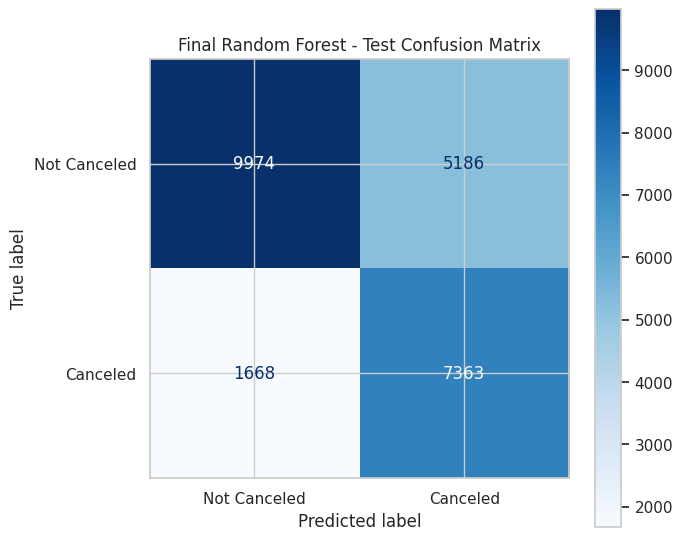

True Negative: 9974
False Positive: 5186
False Negative: 1668
True Positive: 7363


In [ ]:
# STEP 24B: FINAL TEST CONFUSION MATRIX

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test_final, test_pred)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Canceled", "Canceled"]
)

disp.plot(ax=ax, cmap="Blues", values_format="d")

plt.title("Final Random Forest - Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    f"{final_dir}/final_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

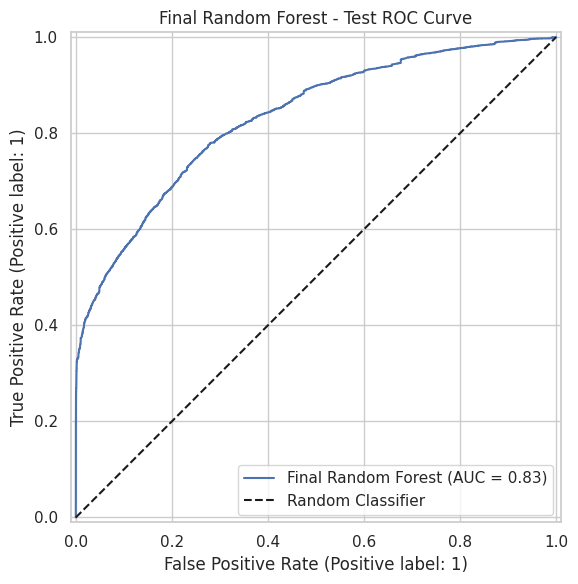

In [ ]:
# STEP 24C: FINAL TEST ROC CURVE

from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(7, 6))

RocCurveDisplay.from_predictions(
    y_test_final,
    test_prob,
    name="Final Random Forest",
    ax=ax
)

ax.plot(
    [0, 1], [0, 1],
    "k--",
    label="Random Classifier"
)

ax.set_title("Final Random Forest - Test ROC Curve")
ax.legend()

plt.tight_layout()
plt.savefig(
    f"{final_dir}/final_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [ ]:
# STEP 24D: SAVE FINAL TEST RESULTS

import json
import os

results_path = os.path.join(
    final_dir, "final_test_results.json"
)

output = {
    "model": "Random Forest",
    "n_features": 19,
    "test_samples": len(X_test_final),
    "threshold": final_threshold,
    "metrics": final_test_results,
    "confusion_matrix": {
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }
}

with open(results_path, "w", encoding="utf-8") as f:
    json.dump(output, f, indent=2)

print("Final test results saved!")
print(results_path)

Final test results saved!
/content/drive/MyDrive/MyDrive/Hotel_Booking_ML/final_experiment/final_test_results.json


## 0. Chuẩn bị môi trường và nạp dữ liệu (Ngày 1)

- Trên **Colab**, tải CSV từ Kaggle rồi upload vào mục **Files** (`/content/hotel_bookings.csv`).
- Trên **máy tính**, đặt CSV tại `data/hotel_bookings.csv`, mở notebook bằng Jupyter.
- Chạy tuần tự các ô từ trên xuống dưới. Dữ liệu Kaggle **không** đóng gói sẵn trong bộ starter.
- Nếu Colab mất phiên làm việc, nhớ sao lưu `.ipynb` và thư mục `outputs/`, `models/`.

In [ ]:
# Nếu Colab báo thiếu thư viện, bỏ dấu # ở dòng sau và chạy:
# %pip -q install pandas numpy matplotlib seaborn scikit-learn joblib streamlit
import json
import warnings
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display

RANDOM_STATE = 42
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
for folder in ("data", "outputs", "outputs/figures", "models"):
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

print("Working folder:", ROOT)
print("scikit-learn:", sklearn.__version__)

paths = [ROOT / "data" / "hotel_bookings.csv", ROOT / "hotel_bookings.csv", Path("/content/hotel_bookings.csv")]
found = next((p for p in paths if p.exists()), None)
if found is None:
    raise FileNotFoundError("Không thấy hotel_bookings.csv. Hãy tải tại Kaggle và upload vào Colab Files hoặc data/.")
raw = pd.read_csv(found)
assert "is_canceled" in raw.columns, "Dataset phải có cột mục tiêu is_canceled"
print("Dataset:", found)
print("Rows, columns:", raw.shape)
display(raw.head())

## 1. Data Understanding & EDA (Ngày 1)

Hãy ghi nhận trong báo cáo: số bản ghi/cột, kiểu dữ liệu, tỷ lệ nhãn, missing values, các cột rò rỉ thông tin và 4 biểu đồ EDA kèm nhận xét **trực tiếp từ kết quả chạy**.

**Không tự động `drop_duplicates()`**: dữ liệu không có ID booking duy nhất, nên hai dòng giống nhau hoàn toàn chưa chắc là một giao dịch bị trùng. Ghi rõ đây là quyết định có chủ ý.

In [ ]:
print("Thông tin bộ dữ liệu:")
raw.info()
print("\nSố dòng trùng toàn bộ trường:", raw.duplicated().sum())
missing = raw.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("missing_count"))
label_summary = raw["is_canceled"].value_counts().sort_index().rename(index={0:"Không hủy",1:"Hủy"})
display(pd.DataFrame({"số lượng": label_summary, "tỷ lệ (%)": (label_summary/len(raw)*100).round(2)}))

In [ ]:
# 4 biểu đồ để đưa thẳng vào báo cáo
sns.set_theme(style="whitegrid")
figdir = ROOT / "outputs" / "figures"

def save_plot(filename):
    plt.tight_layout()
    plt.savefig(figdir / filename, dpi=180, bbox_inches="tight")
    plt.show()

plt.figure(figsize=(6,4))
counts = raw["is_canceled"].value_counts().reindex([0,1])
plt.bar(["Không hủy", "Hủy"], counts.values)
plt.title("Phân phối biến mục tiêu")
plt.ylabel("Số booking")
save_plot("01_target_distribution.png")

hotel_rates = raw.groupby("hotel")["is_canceled"].mean().sort_values(ascending=False)*100
plt.figure(figsize=(6,4))
plt.bar(hotel_rates.index, hotel_rates.values)
plt.title("Tỷ lệ hủy theo loại khách sạn")
plt.ylabel("Tỷ lệ hủy (%)")
save_plot("02_hotel_cancel_rate.png")

months = ["January","February","March","April","May","June","July","August","September","October","November","December"]
monthly = (raw.groupby("arrival_date_month")["is_canceled"].mean()*100).reindex(months)
plt.figure(figsize=(10,4))
plt.plot(monthly.index, monthly.values, marker="o")
plt.xticks(rotation=45)
plt.title("Tỷ lệ hủy theo tháng khách dự kiến đến")
plt.ylabel("Tỷ lệ hủy (%)")
save_plot("03_month_cancel_rate.png")

lead_bins = [-1,7,30,90,180,365,np.inf]
lead_labels = ["0-7", "8-30", "31-90", "91-180", "181-365", ">365"]
lead_group = pd.cut(raw["lead_time"], bins=lead_bins, labels=lead_labels)
lead_rates = raw.groupby(lead_group, observed=True)["is_canceled"].mean()*100
plt.figure(figsize=(8,4))
plt.bar(lead_rates.index.astype(str), lead_rates.values)
plt.title("Tỷ lệ hủy theo số ngày đặt trước")
plt.xlabel("Lead time (ngày)")
plt.ylabel("Tỷ lệ hủy (%)")
save_plot("04_leadtime_cancel_rate.png")

### Ghi nhận kết quả EDA

Sau khi chạy, tự điền những nhận xét **đúng theo các biểu đồ vừa tạo** vào báo cáo:

1. Nhãn hủy chiếm bao nhiêu phần trăm? Có mất cân bằng không?
2. City Hotel và Resort Hotel khác nhau thế nào?
3. Tháng nào có tỷ lệ hủy cao? **Không diễn giải sự khác nhau là quan hệ nhân quả**.
4. Booking đặt trước xa có xu hướng hủy nhiều hơn không?
5. Những cột có missing lớn là gì? Vì sao dùng `SimpleImputer` trên **training data** thay vì xóa toàn bộ dòng?

## 2. Định nghĩa feature và chia dữ liệu (Ngày 2)

**Định nghĩa bài toán:** Phân loại nhị phân tại thời điểm ghi nhận booking, sử dụng những trường thường có trong lúc đặt. Các biến `total_of_special_requests`, `required_car_parking_spaces` được giả định là yêu cầu khách đã cung cấp khi đặt; nếu dữ liệu vận hành không đáp ứng giả định này thì cần loại bỏ.

**Loại khỏi mô hình chính:** `reservation_status`, `reservation_status_date`, `booking_changes`, `assigned_room_type`, `deposit_type`, `days_in_waiting_list`, `adr`, `country`, `agent`, `company`. Một số cột bị bỏ vì có thể thay đổi/hình thành sau lúc đặt; một số khác vì dữ liệu thiếu lớn hoặc cần xác minh thời điểm ghi nhận.

Tách **64% train – 16% validation – 20% test** với `stratify`, `random_state=42`. Test phải giữ nguyên cho đến bước đánh giá cuối.

In [ ]:
from sklearn.model_selection import train_test_split

df = raw.copy()
# Chỉ tạo feature bằng công thức, không học thống kê từ toàn bộ dữ liệu
# Đây là thao tác xác định trước, không gây leakage do fit.
df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
df["total_guests"] = df["adults"] + df["children"].fillna(0) + df["babies"]

numeric_features = [
    "lead_time", "stays_in_weekend_nights", "stays_in_week_nights",
    "adults", "children", "babies", "is_repeated_guest",
    "previous_cancellations", "previous_bookings_not_canceled",
    "required_car_parking_spaces", "total_of_special_requests",
    "arrival_date_day_of_month", "total_nights", "total_guests"
]
cat_features = [
    "hotel", "arrival_date_month", "meal", "market_segment",
    "distribution_channel", "reserved_room_type", "customer_type"
]
features = numeric_features + cat_features
X = df[features].copy()
y = df["is_canceled"].astype(int)
assert set(y.unique()).issubset({0,1})
assert not any(f in features for f in ["reservation_status", "reservation_status_date", "booking_changes", "assigned_room_type"])

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.20, stratify=y_dev, random_state=RANDOM_STATE
)
print("Train:", len(X_train), "| Validation:", len(X_val), "| Test:", len(X_test))
print("Tỷ lệ hủy train/val/test:", y_train.mean().round(4), y_val.mean().round(4), y_test.mean().round(4))

## 3. Preprocessing Pipeline + 4 mô hình (Ngày 2)

- Số: `median imputation` + `StandardScaler`.
- Phân loại: `most_frequent imputation` + `OneHotEncoder(handle_unknown='ignore')`.
- Toàn bộ preprocessing nằm **bên trong Pipeline**. Không fit imputer/scaler/encoder trước khi split.
- So sánh **Dummy baseline**, Logistic Regression, Decision Tree, Random Forest.
- **F1-score trên validation** là tiêu chí chọn mô hình mặc định; ROC-AUC, Precision và Recall cũng phải trình bày để giải thích ưu/nhược điểm.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score,
                             confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipe, numeric_features),
    ("categorical", cat_pipe, cat_features),
])

classifiers = {
    "Dummy Baseline": DummyClassifier(strategy="prior"),
    "Logistic Regression": LogisticRegression(max_iter=500, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, min_samples_leaf=40,
                                            class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=120, max_depth=14,
                                             min_samples_leaf=6, class_weight="balanced_subsample",
                                             n_jobs=-1, random_state=RANDOM_STATE),
}

def evaluate(model, X_part, y_part):
    pred = model.predict(X_part)
    proba = model.predict_proba(X_part)[:,1]
    return {
        "Accuracy": accuracy_score(y_part, pred),
        "Precision": precision_score(y_part, pred, zero_division=0),
        "Recall": recall_score(y_part, pred, zero_division=0),
        "F1": f1_score(y_part, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_part, proba),
        "PR_AUC": average_precision_score(y_part, proba),
    }

trained = {}
results = []
for name, clf in classifiers.items():
    print("Training:", name)
    pipe = Pipeline([("preprocess", clone(preprocessor)), ("model", clone(clf))])
    pipe.fit(X_train, y_train)
    trained[name] = pipe
    results.append({"Model": name, **evaluate(pipe, X_val, y_val)})

leaderboard = pd.DataFrame(results).sort_values("F1", ascending=False).reset_index(drop=True)
display(leaderboard.round(4))
leaderboard.to_csv(ROOT / "outputs" / "validation_comparison.csv", index=False)
best_name = leaderboard.iloc[0]["Model"]
best_pipeline = trained[best_name]
print("Tốt nhất trên validation theo F1:", best_name)

## 4. Tuning có kiểm soát (Ngày 3 — tùy chọn)

Trước khi xem kết quả test, có thể tinh chỉnh Random Forest trong **train** bằng 3-fold CV, rồi so với mô hình hiện tại trên **validation**. Để tiết kiệm thời gian, mặc định `RUN_TUNING = False`. Chuyển thành `True` khi các phần chính đã xong.

Đừng chạy tuning liên tục chỉ để tìm con số cao. Ghi rõ không gian tham số, `scoring`, số fold và chi phí tính toán.

In [ ]:
RUN_TUNING = False
if RUN_TUNING:
    from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
    rf_pipe = Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", RandomForestClassifier(class_weight="balanced_subsample",
                                          n_jobs=-1, random_state=RANDOM_STATE))
    ])
    search = RandomizedSearchCV(
        rf_pipe,
        param_distributions={
            "model__n_estimators": [80, 120, 160],
            "model__max_depth": [10, 14, 18],
            "model__min_samples_leaf": [3, 6, 10],
        },
        n_iter=5, scoring="f1",
        cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
        n_jobs=1, random_state=RANDOM_STATE, verbose=1,
    )
    search.fit(X_train, y_train)
    tuned = search.best_estimator_
    tuned_metrics = evaluate(tuned, X_val, y_val)
    print("Best params:", search.best_params_)
    print("Tuned RF validation:", tuned_metrics)
    if tuned_metrics["F1"] > float(leaderboard.iloc[0]["F1"]):
        best_name = "Random Forest (Tuned)"
        best_pipeline = tuned
        print("Tuned model được chọn trên validation")
    else:
        print("Giữ mô hình tốt nhất ban đầu")
else:
    print("Bỏ qua tuning để ưu tiên hoàn thiện đồ án.")

## 5. Permutation Importance trên validation (Ngày 3)

Tính mức giảm ROC-AUC khi hoán đổi từng biến đầu vào (trên mẫu validation), nhằm giải thích **độ quan trọng cho dự đoán**, không khẳng định quan hệ nhân quả.

Lưu ý: việc chọn mô hình đã dựa trên validation, nên phân tích này là diễn giải thăm dò; không coi là đánh giá độc lập.

In [ ]:
from sklearn.inspection import permutation_importance
sample_n = min(1500, len(X_val))
X_imp = X_val.sample(n=sample_n, random_state=RANDOM_STATE)
y_imp = y_val.loc[X_imp.index]
imp = permutation_importance(best_pipeline, X_imp, y_imp, n_repeats=2,
                             random_state=RANDOM_STATE, scoring="roc_auc", n_jobs=1)
importance = pd.DataFrame({"feature": features,
                           "importance_mean": imp.importances_mean,
                           "importance_std": imp.importances_std}).sort_values("importance_mean", ascending=False)
display(importance.head(15).round(4))
importance.to_csv(ROOT / "outputs" / "feature_importance.csv", index=False)
plt.figure(figsize=(9,5))
top = importance.head(12).iloc[::-1]
plt.barh(top["feature"], top["importance_mean"])
plt.xlabel("Giảm ROC-AUC trung bình khi tráo feature")
plt.title("Permutation Importance (validation)")
save_plot("05_feature_importance.png")

## 6. Đánh giá test một lần và lưu mô hình cuối (Ngày 3)

Chỉ thực hiện phần này **sau khi đã chốt mô hình/siêu tham số**. Fit lại trên toàn bộ **dev = train + validation**, đánh giá trên **test chưa hề sử dụng để chọn mô hình**.

In [ ]:
final_model = clone(best_pipeline)
final_model.fit(X_dev, y_dev)
test_scores = evaluate(final_model, X_test, y_test)
print("Mô hình cuối:", best_name)
print("Test scores:", {k:round(v,4) for k,v in test_scores.items()})
print(classification_report(y_test, final_model.predict(X_test),
                            target_names=["Không hủy", "Hủy"], zero_division=0))

fig, ax = plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay.from_estimator(final_model, X_test, y_test,
                                      display_labels=["Không hủy", "Hủy"],
                                      cmap="Blues", ax=ax, values_format="d")
ax.set_title("Confusion Matrix — Test")
save_plot("06_test_confusion_matrix.png")

fig, ax = plt.subplots(figsize=(6,5))
RocCurveDisplay.from_estimator(final_model, X_test, y_test, ax=ax)
ax.plot([0,1],[0,1],"k--",label="Random")
ax.set_title("ROC Curve — Test")
ax.legend()
save_plot("07_test_roc.png")

joblib.dump(final_model, ROOT / "models" / "best_model.joblib")
with open(ROOT / "outputs" / "final_test_metrics.json", "w", encoding="utf-8") as f:
    json.dump({"model": best_name, **{k:float(v) for k,v in test_scores.items()}},
              f, ensure_ascii=False, indent=2)

def value_for_json(v):
    return str(v) if pd.notna(v) else "Unknown"

defaults = {col: float(X_dev[col].median()) for col in numeric_features}
defaults.update({col: value_for_json(X_dev[col].mode(dropna=True).iloc[0]) for col in cat_features})
metadata = {"features": features, "numeric_features": numeric_features,
            "cat_features": cat_features, "defaults": defaults,
            "selected_model": best_name}
with open(ROOT / "models" / "feature_defaults.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)
print("Đã lưu mô hình, kết quả và metadata vào models/ + outputs/")

## 7. Bài học, hạn chế & tiếp theo (Ngày 4)

Trong báo cáo, phải ghi:

1. **Những gì đã làm:** Bài toán, lý do chọn dataset, lựa chọn features, Pipeline, 4 mô hình, tiêu chí chọn mô hình, kết quả val/test.
2. **Những gì mô hình cho thấy:** 2–3 nhận xét từ EDA, yếu tố dự đoán quan trọng nhất theo biểu đồ, phân tích confusion matrix (FP/FN).
3. **Giới hạn:** Dữ liệu lịch sử của 2 khách sạn tại Bồ Đào Nha (2015–2017), bộ dữ liệu đã được chuẩn bị với thời điểm trước ngày khách tới, nên **không bảo đảm** tái tạo chính xác thông tin tại thời điểm booking; random split không phải kiểm định triển khai tương lai; có thể có booking giống nhau mà không có booking ID duy nhất để phân biệt.
4. **Hướng phát triển:** Kiểm thử time-based holdout, hiệu chỉnh xác suất, làm rõ thời điểm ghi nhận biến, triển khai thực tế và monitoring data drift.
5. **Minh họa demo** (nếu muốn): Chạy `streamlit run app.py` từ thư mục gốc sau khi đã tạo `models/best_model.joblib` và `models/feature_defaults.json`.

**KHÔNG bịa số liệu.** Hãy lấy trực tiếp từ `outputs/validation_comparison.csv`, `outputs/final_test_metrics.json` và các biểu đồ PNG.